<a href="https://colab.research.google.com/github/IvanovaKaryna/123/blob/main/%D0%9B%D0%A010_%D0%86%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Іванова Карина

**Група:** ФІТ 3-10

**Дата:** 09.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import random
import os

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Бібліотеки успішно імпортовано!")


TensorFlow version: 2.21.0
NumPy version: 2.4.6
Бібліотеки успішно імпортовано!


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
# Завантаження Fashion MNIST
fashion_mnist = keras.datasets.fashion_mnist

(x_train_full, y_train_full), (x_test, y_test) = fashion_mnist.load_data()

class_names = [
    'Футболка',
    'Штани',
    'Светр',
    'Сукня',
    'Пальто',
    'Сандалі',
    'Сорочка',
    'Кросівки',
    'Сумка',
    'Черевики'
]

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train_full
)

print("Розмір навчальної вибірки:", x_train.shape)
print("Розмір міток навчальної вибірки:", y_train.shape)
print("Розмір валідаційної вибірки:", x_val.shape)
print("Розмір міток валідаційної вибірки:", y_val.shape)
print("Розмір тестової вибірки:", x_test.shape)
print("Розмір міток тестової вибірки:", y_test.shape)
print("\nНазви класів:")
for i, name in enumerate(class_names):
    print(i, "-", name)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Розмір навчальної вибірки: (48000, 28, 28)
Розмір міток навчальної вибірки: (48000,)
Розмір валідаційної вибірки: (12000, 28, 28)
Розмір міток валідаційної вибірки: (12000,)
Розмір тестової вибірки: (10000, 28, 28)
Розмір міток тестової вибірки: (10000,)

Назви класів:
0 - Футболка
1 - Штани
2 - Светр
3 - Сукня
4 - Пальто
5 - Сандалі
6 - Сорочка
7 - Кросівки
8 - Сумка
9 - Черевики


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

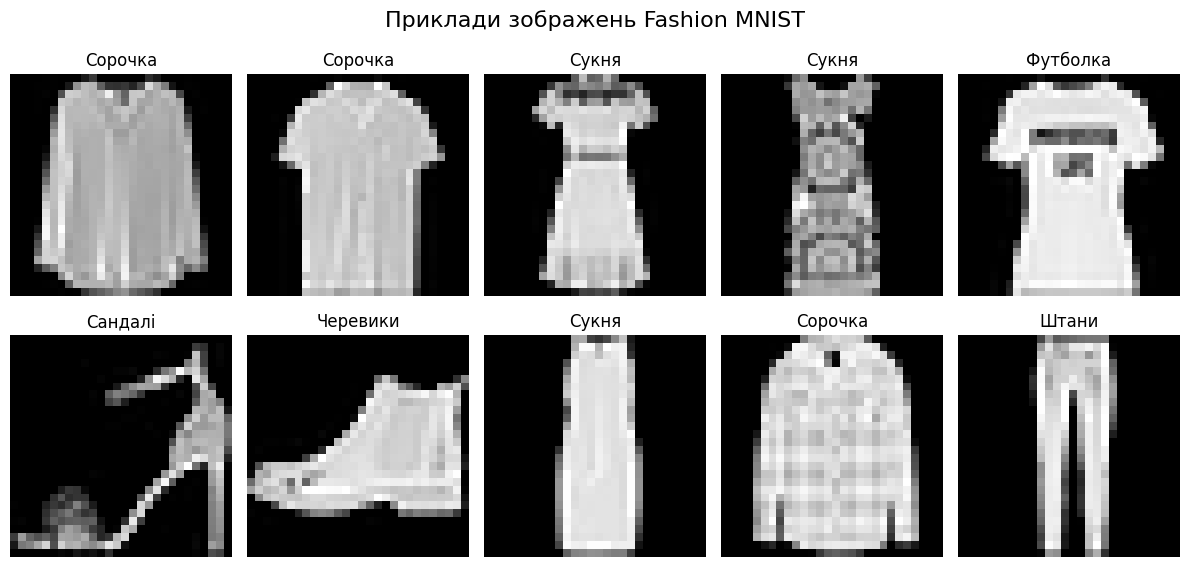

In [3]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.suptitle("Приклади зображень Fashion MNIST", fontsize=16)
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train = x_train.astype('float32') / 255.0
x_val = x_val.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Мінімальне значення:", x_train.min())
print("Максимальне значення:", x_train.max())
print("Тип даних:", x_train.dtype)
print("Навчальні дані:", x_train.shape)
print("Валідаційні дані:", x_val.shape)
print("Тестові дані:", x_test.shape)

Мінімальне значення: 0.0
Максимальне значення: 1.0
Тип даних: float32
Навчальні дані: (48000, 28, 28)
Валідаційні дані: (12000, 28, 28)
Тестові дані: (10000, 28, 28)


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),

    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Модель успішно створена та скомпільована!")

Модель успішно створена та скомпільована!


Для побудови нейронної мережі було використано два приховані шари з 256 та 128 нейронами. Така кількість нейронів дозволяє моделі виявляти характерні ознаки зображень. Функцію активації ReLU використано для навчання нелінійних залежностей. Dropout зі значеннями 0,2 та 0,3 допомагає запобігти перенавчанню. Оптимізатор Adam зі швидкістю навчання 0,001 забезпечує ефективне налаштування ваг моделі.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history = model.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)
print("Навчання завершено!")
print("Кількість епох:", len(history.history['loss']))

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.7775 - loss: 0.6324 - val_accuracy: 0.8493 - val_loss: 0.4115 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8427 - loss: 0.4331 - val_accuracy: 0.8651 - val_loss: 0.3627 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8582 - loss: 0.3882 - val_accuracy: 0.8733 - val_loss: 0.3478 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8673 - loss: 0.3614 - val_accuracy: 0.8788 - val_loss: 0.3304 - learning_rate: 0.0010
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8739 - loss: 0.3439 - val_accuracy: 0.8853 - val_loss: 0.3199 - learning_rate: 0.0010
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8774 - loss: 0.3288 - val_accuracy: 0.8814 - val_loss: 0.3231 - learning_rate: 0.0010
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8826 - loss: 0.

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()

print("\nКількість шарів:", len(model.layers))

print("Загальна кількість параметрів:",
      model.count_params())

print("Навчувані параметри:",
      sum(np.prod(w.shape) for w in model.trainable_weights))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)


Кількість шарів: 6
Загальна кількість параметрів: 235146
Навчувані параметри: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
os.makedirs("results", exist_ok=True)

model.save("results/fashion_mnist_model.keras")

print("Модель збережено у форматі .keras")

Модель збережено у форматі .keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

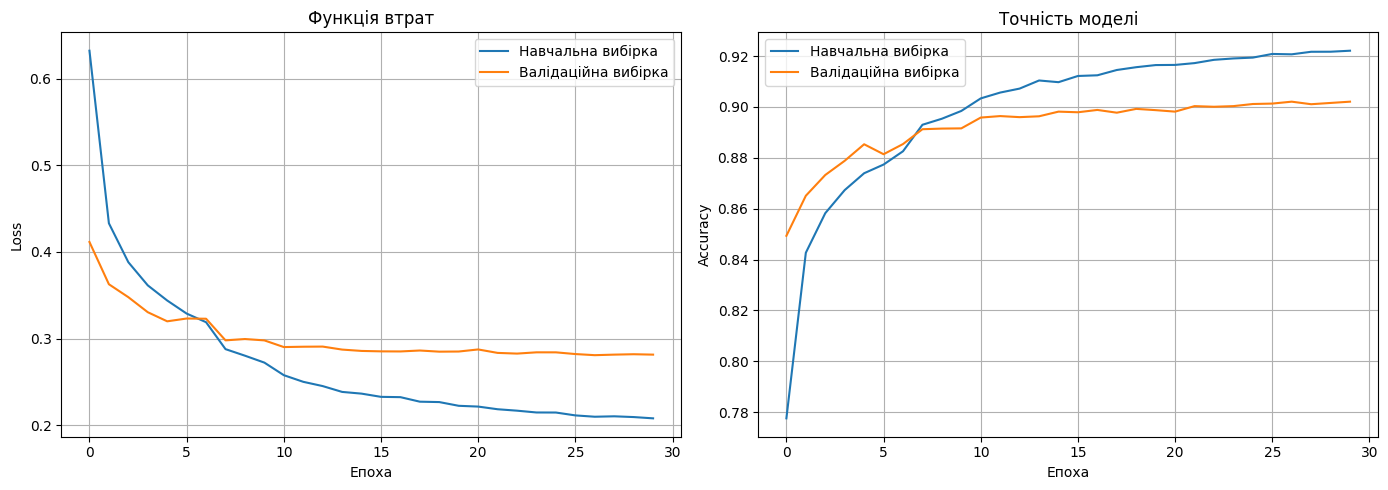

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
plt.figure(figsize=(14, 5))

# Графік функції втрат
plt.subplot(1, 2, 1)

plt.plot(history.history['loss'], label='Навчальна вибірка')
plt.plot(history.history['val_loss'], label='Валідаційна вибірка')

plt.title('Функція втрат')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid()

# Графік точності
plt.subplot(1, 2, 2)

plt.plot(history.history['accuracy'], label='Навчальна вибірка')
plt.plot(history.history['val_accuracy'], label='Валідаційна вибірка')

plt.title('Точність моделі')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.tight_layout()
plt.savefig("results/task1_training_graphs.png")
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Тестова втрата (loss):", round(test_loss, 4))
print("Тестова точність (accuracy):", round(test_accuracy, 4))

y_pred_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

print("\nКласифікаційний звіт:")

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

if test_accuracy >= 0.87:
    print("Вимогу щодо точності 0.87 ВИКОНАНО!")
else:
    print("Вимогу щодо точності 0.87 НЕ ВИКОНАНО.")

Тестова втрата (loss): 0.313
Тестова точність (accuracy): 0.8931

Класифікаційний звіт:
              precision    recall  f1-score   support

    Футболка     0.8433    0.8450    0.8442      1000
       Штани     0.9908    0.9720    0.9813      1000
       Светр     0.8084    0.8230    0.8157      1000
       Сукня     0.8946    0.9000    0.8973      1000
      Пальто     0.8062    0.8360    0.8208      1000
     Сандалі     0.9758    0.9670    0.9714      1000
     Сорочка     0.7276    0.6890    0.7078      1000
    Кросівки     0.9441    0.9630    0.9535      1000
       Сумка     0.9712    0.9780    0.9746      1000
    Черевики     0.9667    0.9580    0.9623      1000

    accuracy                         0.8931     10000
   macro avg     0.8929    0.8931    0.8929     10000
weighted avg     0.8929    0.8931    0.8929     10000

Вимогу щодо точності 0.87 ВИКОНАНО!


### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

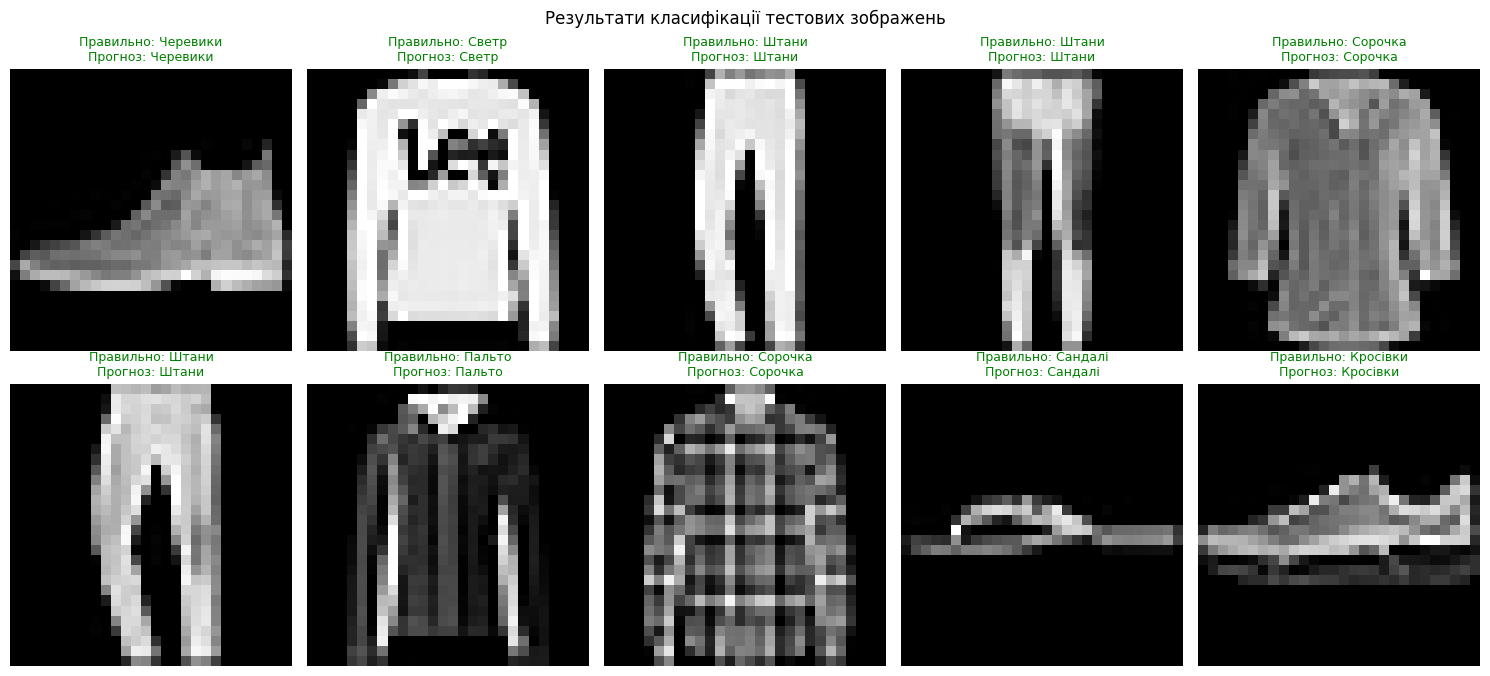

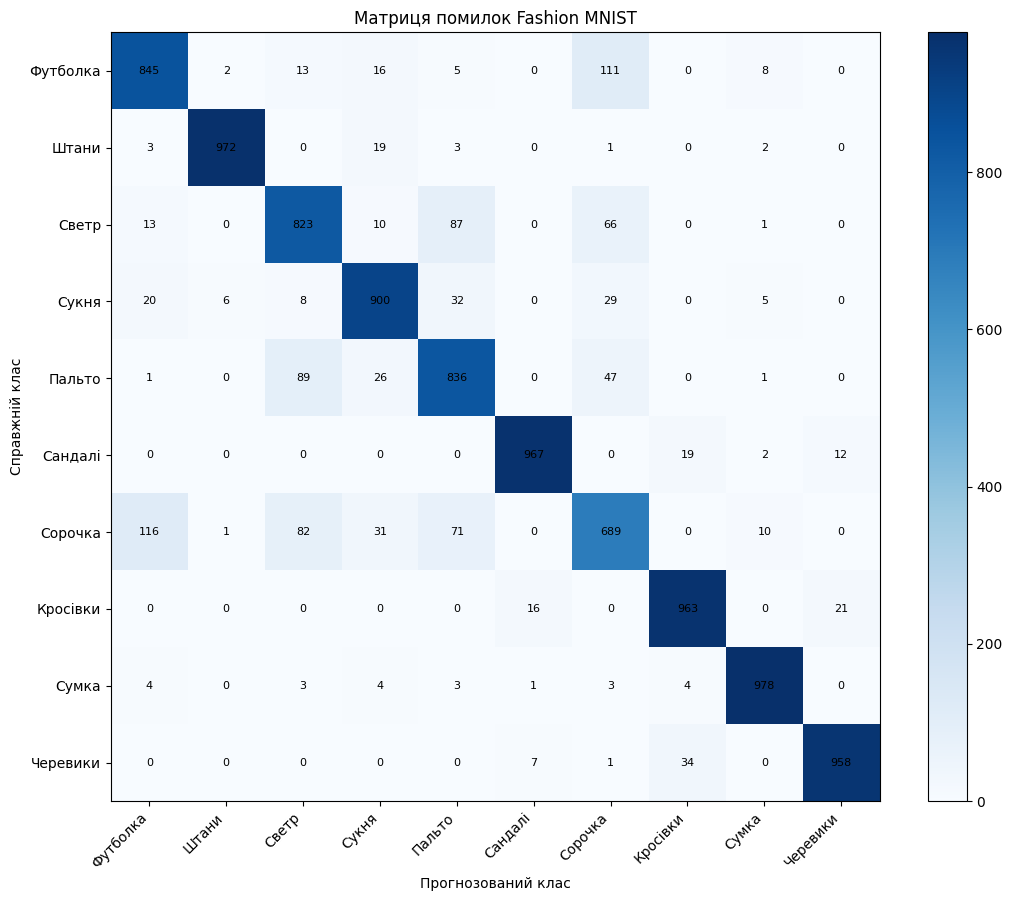

Кількість помилок за класами:
Футболка : 155
Штани : 28
Светр : 177
Сукня : 100
Пальто : 164
Сандалі : 33
Сорочка : 311
Кросівки : 37
Сумка : 22
Черевики : 42

Найскладніші класи за кількістю помилок:
Сорочка - 311 помилок
Светр - 177 помилок
Пальто - 164 помилок


In [14]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(15, 7))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap='gray')

    true_label = y_test[i]
    predicted_label = y_pred[i]

    color = 'green' if true_label == predicted_label else 'red'

    plt.title(
        f"Правильно: {class_names[true_label]}\n"
        f"Прогноз: {class_names[predicted_label]}",
        color=color,
        fontsize=9
    )

    plt.axis('off')

plt.suptitle("Результати класифікації тестових зображень")
plt.tight_layout()
plt.savefig("results/task1_predictions.png")
plt.show()
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(11, 9))

plt.imshow(cm, cmap='Blues')
plt.colorbar()

plt.xticks(range(10), class_names, rotation=45, ha='right')
plt.yticks(range(10), class_names)

plt.xlabel("Прогнозований клас")
plt.ylabel("Справжній клас")
plt.title("Матриця помилок Fashion MNIST")

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j],
                 ha='center', va='center', fontsize=8)

plt.tight_layout()
plt.savefig("results/task1_confusion_matrix.png")
plt.show()

errors = cm.sum(axis=1) - np.diag(cm)

print("Кількість помилок за класами:")

for i, count in enumerate(errors):
    print(class_names[i], ":", count)

print("\nНайскладніші класи за кількістю помилок:")

for i in np.argsort(errors)[-3:][::-1]:
    print(class_names[i], "-", errors[i], "помилок")

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Під час виконання першого завдання я створила та навчила нейронну мережу для класифікації зображень Fashion MNIST.

Найбільше помилок модель допускала під час розпізнавання схожих між собою предметів одягу, наприклад сорочок, футболок та светрів. Це пов'язано з тим, що деякі зображення мають схожі форми та особливості.

Отриману точність я порівняла з необхідним значенням 0,87. Якщо точність становить не менше 0,87, то вимогу виконано.

У результаті я навчилася створювати нейронну мережу, оцінювати її точність та аналізувати помилки класифікації.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [15]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner

import keras_tuner as kt

from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

print("Keras Tuner успішно встановлено!")

Keras Tuner успішно встановлено!


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [16]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
print("Навчальна вибірка:", x_train.shape)
print("Валідаційна вибірка:", x_val.shape)
print("Тестова вибірка:", x_test.shape)
print("\nМінімальне значення:", x_train.min())
print("Максимальне значення:", x_train.max())
print("\nНавчальні та валідаційні дані підготовлені.")
print("Тестові дані не використовуються під час пошуку.")

Навчальна вибірка: (48000, 28, 28)
Валідаційна вибірка: (12000, 28, 28)
Тестова вибірка: (10000, 28, 28)

Мінімальне значення: 0.0
Максимальне значення: 1.0

Навчальні та валідаційні дані підготовлені.
Тестові дані не використовуються під час пошуку.


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [17]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):

    model = keras.Sequential()

    model.add(keras.Input(shape=(28, 28)))

    model.add(Flatten())

    num_layers = hp.Int(
        'num_layers',
        min_value=1,
        max_value=3,
        step=1
    )

    for i in range(num_layers):

        units = hp.Int(
            f'units_{i}',
            min_value=32,
            max_value=512,
            step=32
        )

        model.add(Dense(
            units,
            activation='relu',
            kernel_regularizer=l2(0.0001)
        ))

        model.add(Dropout(0.2))

    model.add(Dense(10, activation='softmax'))

    learning_rate = hp.Choice(
        'learning_rate',
        values=[0.01, 0.001, 0.0001]
    )
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

print("Функцію build_model успішно створено!")

Функцію build_model успішно створено!


### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [18]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='keras_tuner_results',
    project_name='fashion_mnist'
)

print("Пошук гіперпараметрів налаштовано!")

tuner.search_space_summary()

Пошук гіперпараметрів налаштовано!
Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [22]:
tuner_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

tuner_reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

tuner.search(
    x_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[
        tuner_early_stopping,
        tuner_reduce_lr
    ],
    verbose=1
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("\nНайкращі параметри:")

print("Кількість прихованих шарів:",
      best_hp.get('num_layers'))

print("Швидкість навчання:",
      best_hp.get('learning_rate'))

best_units = []

for i in range(best_hp.get('num_layers')):
    units = best_hp.get(f'units_{i}')
    best_units.append(units)
    print(f"Шар {i + 1}: {units} нейронів")

best_model = build_model(best_hp)

print("\nАрхітектура найкращої моделі:")
best_model.summary()

best_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

best_reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

best_history = best_model.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[
        best_early_stopping,
        best_reduce_lr
    ],
    verbose=1
)

print("\nНавчання найкращої моделі завершено!")

print("Кількість епох:",
      len(best_history.history['loss']))

best_model.save("results/fashion_mnist_best_model.keras")

print("Найкращу модель збережено!")


Найкращі параметри:
Кількість прихованих шарів: 1
Швидкість навчання: 0.001
Шар 1: 448 нейронів

Архітектура найкращої моделі:


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 448)            │       351,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         4,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,170 (1.36 MB)

 Trainable params: 356,170 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8042 - loss: 0.6106 - val_accuracy: 0.8353 - val_loss: 0.5016 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8524 - loss: 0.4624 - val_accuracy: 0.8556 - val_loss: 0.4471 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8654 - loss: 0.4268 - val_accuracy: 0.8684 - val_loss: 0.4107 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8719 - loss: 0.4030 - val_accuracy: 0.8733 - val_loss: 0.4054 - learning_rate: 0.0010
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8774 - loss: 0.3891 - val_accuracy: 0.8807 - val_loss: 0.3859 - learning_rate: 0.0010
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8816 - loss: 0.3772 - val_accuracy: 0.8748 - val_loss: 0.3977 - learning_rate: 0.0010
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8852 - loss: 0.

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Результати найкращої моделі:
Test loss: 0.3503
Test accuracy: 0.8919


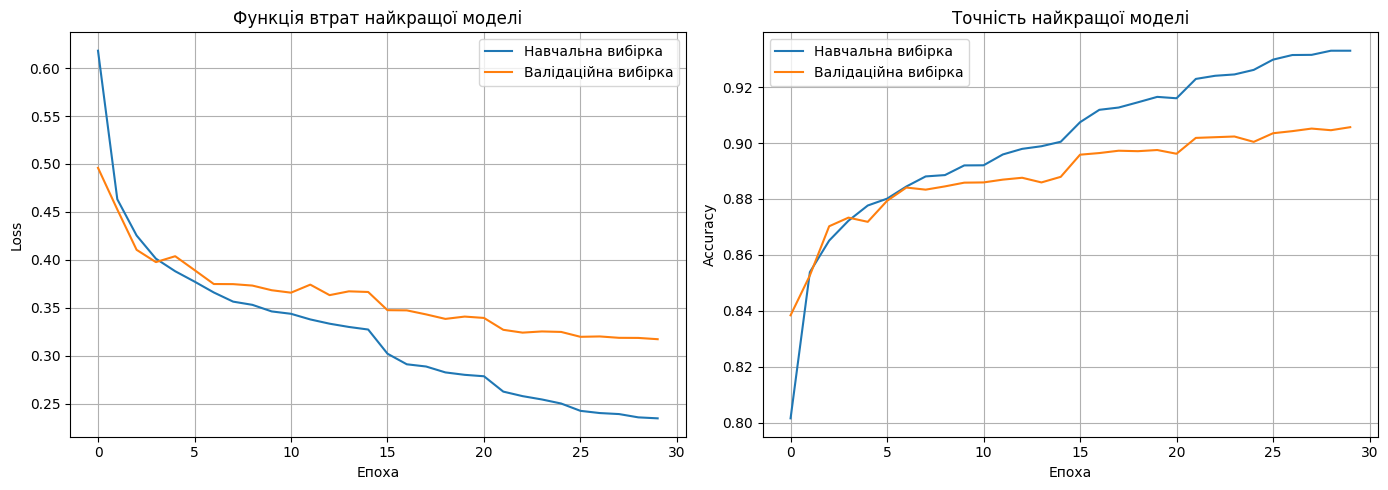

In [21]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
best_test_loss, best_test_accuracy = best_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Результати найкращої моделі:")
print("Test loss:", round(best_test_loss, 4))
print("Test accuracy:", round(best_test_accuracy, 4))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    best_history.history['loss'],
    label='Навчальна вибірка'
)

plt.plot(
    best_history.history['val_loss'],
    label='Валідаційна вибірка'
)

plt.title('Функція втрат найкращої моделі')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    best_history.history['accuracy'],
    label='Навчальна вибірка'
)

plt.plot(
    best_history.history['val_accuracy'],
    label='Валідаційна вибірка'
)

plt.title('Точність найкращої моделі')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.tight_layout()
plt.savefig("results/task2_training_graphs.png")
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256, 128 | 448 |
| Швидкість навчання | 0,001 | 0.001 |
| Точність на тестовій вибірці (accuracy) | 0.8931	 |0.8919 |
| Втрати на тестовій вибірці (loss) | 0.3130 | 0.3503 |
| Кількість епох навчання | 30 | 30 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
1. Чи досягнуто точності не нижче 0,87 у завданні 1?

Так, у першому завданні вдалося досягти точності 0,8931, що перевищує встановлену вимогу 0,87. Отже, модель успішно виконала поставлене завдання.

2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?

Ні, після автоматизованого налаштування гіперпараметрів точність становила 0,8919, тоді як початкова модель показала 0,8931. Різниця незначна, але початкова модель виявилася трохи точнішою. Водночас обидві моделі досягли необхідного рівня точності.

3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?

За результатами Keras Tuner найкращою конфігурацією стала модель з одним прихованим шаром на 448 нейронів і швидкістю навчання 0,001. Результати можуть відрізнятися між запусками через випадкову ініціалізацію ваг, порядок подачі даних під час навчання та особливості процесу оптимізації.

4. Які класи Fashion MNIST класифікувати найскладніше?

Це питання поки що не можна заповнити достовірно лише за загальною точністю моделей. Потрібні результати матриці помилок або вивід із назвами класів та кількістю помилкових класифікацій. Не будемо вигадувати ці дані.
Під час виконання лабораторної роботи я побудувала нейронну мережу для класифікації зображень одягу з набору даних Fashion MNIST за допомогою бібліотеки Keras. Я виконала попередню обробку даних, нормалізацію зображень, створила та навчила модель, а також оцінила її якість на тестовій вибірці.

У першому завданні модель із двома прихованими шарами досягла точності 89,31%, що відповідає встановленій вимозі. У другому завданні я використала Keras Tuner для автоматизованого підбору гіперпараметрів. Найкращою виявилася конфігурація з одним прихованим шаром на 448 нейронів та швидкістю навчання 0,001. Її точність становила 89,19%.

Порівняння показало, що автоматизоване налаштування не забезпечило покращення точності, але дозволило знайти іншу конфігурацію нейронної мережі з близьким результатом. У результаті роботи я отримала практичний досвід створення, навчання та оцінювання нейронних мереж, а також використання Keras Tuner для підбору гіперпараметрів.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.